# Lab | Data Structuring and Combining Data

## Challenge 1: Combining & Cleaning Data

In this challenge, we will be working with the customer data from an insurance company, as we did in the two previous labs. The data can be found here:
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv

But this time, we got new data, which can be found in the following 2 CSV files located at the links below.

- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv

Note that you'll need to clean and format the new data.

Observation:
- One option is to first combine the three datasets and then apply the cleaning function to the new combined dataset
- Another option would be to read the clean file you saved in the previous lab, and just clean the two new files and concatenate the three clean datasets

In [2]:
import pandas as pd

# Load cleaned dataset from previous lab
df1 = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv")

# Load new datasets
url2 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv"
url3 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv"

df2 = pd.read_csv(url2)
df3 = pd.read_csv(url3)

# Check columns
print(df1.columns)
print(df2.columns)
print(df3.columns)

Index(['Customer', 'ST', 'GENDER', 'Education', 'Customer Lifetime Value',
       'Income', 'Monthly Premium Auto', 'Number of Open Complaints',
       'Policy Type', 'Vehicle Class', 'Total Claim Amount'],
      dtype='object')
Index(['Customer', 'ST', 'GENDER', 'Education', 'Customer Lifetime Value',
       'Income', 'Monthly Premium Auto', 'Number of Open Complaints',
       'Total Claim Amount', 'Policy Type', 'Vehicle Class'],
      dtype='object')
Index(['Customer', 'State', 'Customer Lifetime Value', 'Education', 'Gender',
       'Income', 'Monthly Premium Auto', 'Number of Open Complaints',
       'Policy Type', 'Total Claim Amount', 'Vehicle Class'],
      dtype='object')


In [3]:
def clean_insurance_data(df):

    # Clean column names
    df.columns = (
        df.columns
        .str.lower()
        .str.strip()
        .str.replace(" ", "_")
        .str.replace("st", "state")
    )

    # Clean gender
    if "gender" in df.columns:
        df["gender"] = df["gender"].replace({
            "F": "F",
            "Femal": "F",
            "female": "F",
            "M": "M",
            "Male": "M"
        })

    # Clean state
    if "state" in df.columns:
        df["state"] = df["state"].replace({
            "AZ": "Arizona",
            "Cali": "California",
            "WA": "Washington"
        })

    # Clean education
    if "education" in df.columns:
        df["education"] = df["education"].replace({
            "Bachelors": "Bachelor"
        })

    # Clean customer lifetime value
    if "customer_lifetime_value" in df.columns:
        df["customer_lifetime_value"] = (
            df["customer_lifetime_value"]
            .astype(str)
            .str.replace("%", "", regex=False)
        )
        df["customer_lifetime_value"] = pd.to_numeric(
            df["customer_lifetime_value"],
            errors="coerce"
        )

    # Clean number of open complaints
    if "number_of_open_complaints" in df.columns:
        df["number_of_open_complaints"] = (
            df["number_of_open_complaints"]
            .astype(str)
            .str.split("/")
            .str[1]
        )

        df["number_of_open_complaints"] = pd.to_numeric(
            df["number_of_open_complaints"],
            errors="coerce"
        )

    # Clean vehicle class
    if "vehicle_class" in df.columns:
        df["vehicle_class"] = df["vehicle_class"].replace({
            "Sports Car": "Luxury",
            "Luxury SUV": "Luxury",
            "Luxury Car": "Luxury"
        })

    # Handle missing values
    numerical_cols = df.select_dtypes(include="number").columns

    for col in numerical_cols:
        df[col] = df[col].fillna(df[col].median())

    categorical_cols = df.select_dtypes(include="object").columns

    for col in categorical_cols:
        df[col] = df[col].fillna(df[col].mode()[0])

    # Remove duplicates
    df = df.drop_duplicates()
    df = df.reset_index(drop=True)

    # Convert numeric columns to integers
    numerical_cols = df.select_dtypes(include="number").columns
    df[numerical_cols] = df[numerical_cols].astype(int)

    return df

In [6]:
# Concatenate all cleaned datasets

final_df = pd.concat(
    [df1, df2_clean, df3_clean],
    ignore_index=True
)

# Check final shape
print(final_df.shape)

# Check first rows
final_df.head()

NameError: name 'df3_clean' is not defined

In [ ]:
# Check missing values
print(final_df.isnull().sum())

# Check duplicates
print("Duplicates:", final_df.duplicated().sum())

# Check data types
print(final_df.dtypes)

In [ ]:
final_df.to_csv(
    "insurance_customer_final_cleaned.csv",
    index=False
)

# Challenge 2: Structuring Data

In this challenge, we will continue to work with customer data from an insurance company, but we will use a dataset with more columns, called marketing_customer_analysis.csv, which can be found at the following link:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv

This dataset contains information such as customer demographics, policy details, vehicle information, and the customer's response to the last marketing campaign. Our goal is to explore and analyze this data by performing data cleaning, formatting, and structuring.

In [7]:
import pandas as pd

# Load dataset
url = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv"

df = pd.read_csv(url)

# Display first rows
df.head()

,unnamed:_0,customer,state,customer_lifetime_value,response,coverage,education,effective_to_date,employmentstatus,gender,...,number_of_policies,policy_type,policy,renew_offer_type,sales_channel,total_claim_amount,vehicle_class,vehicle_size,vehicle_type,month
0,0,DK49336,Arizona,4809.216960,No,Basic,College,2011-02-18,Employed,M,...,9,Corporate Auto,Corporate L3,Offer3,Agent,292.800000,Four-Door Car,Medsize,A,2
1,1,KX64629,California,2228.525238,No,Basic,College,2011-01-18,Unemployed,F,...,1,Personal Auto,Personal L3,Offer4,Call Center,744.924331,Four-Door Car,Medsize,A,1
2,2,LZ68649,Washington,14947.917300,No,Basic,Bachelor,2011-02-10,Employed,M,...,2,Personal Auto,Personal L3,Offer3,Call Center,480.000000,SUV,Medsize,A,2
3,3,XL78013,Oregon,22332.439460,Yes,Extended,College,2011-01-11,Employed,M,...,2,Corporate Auto,Corporate L3,Offer2,Branch,484.013411,Four-Door Car,Medsize,A,1
4,4,QA50777,Oregon,9025.067525,No,Premium,Bachelor,2011-01-17,Medical Leave,F,...,7,Personal Auto,Personal L2,Offer1,Branch,707.925645,Four-Door Car,Medsize,A,1


In [8]:
# Check number of rows and columns
print(df.shape)

# Check column names
print(df.columns)

# Check data types and missing values
df.info()

(10910, 27)
Index(['unnamed:_0', 'customer', 'state', 'customer_lifetime_value',
       'response', 'coverage', 'education', 'effective_to_date',
       'employmentstatus', 'gender', 'income', 'location_code',
       'marital_status', 'monthly_premium_auto', 'months_since_last_claim',
       'months_since_policy_inception', 'number_of_open_complaints',
       'number_of_policies', 'policy_type', 'policy', 'renew_offer_type',
       'sales_channel', 'total_claim_amount', 'vehicle_class', 'vehicle_size',
       'vehicle_type', 'month'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10910 entries, 0 to 10909
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   unnamed:_0                     10910 non-null  int64  
 1   customer                       10910 non-null  object 
 2   state                          10910 non-null  object 
 3   customer_lifetime_value

In [9]:
df.describe()

,unnamed:_0,customer_lifetime_value,income,monthly_premium_auto,months_since_last_claim,months_since_policy_inception,number_of_open_complaints,number_of_policies,total_claim_amount,month
count,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000
mean,5454.500000,8018.241094,37536.284785,93.196059,15.149071,48.091934,0.384256,2.979193,434.888330,1.466728
std,3149.590053,6885.081434,30359.195670,34.442532,9.783520,27.940675,0.885589,2.399359,292.180556,0.498915
min,0.000000,1898.007675,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007,1.000000
25%,2727.250000,4014.453113,0.000000,68.000000,7.000000,24.000000,0.000000,1.000000,271.082527,1.000000
50%,5454.500000,5771.147235,33813.500000,83.000000,15.000000,48.000000,0.000000,2.000000,382.564630,1.000000
75%,8181.750000,8992.779137,62250.750000,109.000000,23.000000,71.000000,0.384256,4.000000,547.200000,2.000000
max,10909.000000,83325.381190,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678,2.000000


In [10]:
df.describe(include="object")

,customer,state,response,coverage,education,effective_to_date,employmentstatus,gender,location_code,marital_status,policy_type,policy,renew_offer_type,sales_channel,vehicle_class,vehicle_size,vehicle_type
count,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910,10910
unique,9134,5,2,3,5,59,5,2,3,3,3,9,4,4,6,3,1
top,ID89933,California,No,Basic,Bachelor,2011-01-10,Employed,F,Suburban,Married,Personal Auto,Personal L3,Offer1,Agent,Four-Door Car,Medsize,A
freq,7,4183,9444,6660,3272,239,6789,5573,6902,6319,8128,4118,4483,4121,5834,7873,10910


In [11]:
# Count null values
df.isnull().sum()

unnamed:_0                       0
customer                         0
state                            0
customer_lifetime_value          0
response                         0
coverage                         0
education                        0
effective_to_date                0
employmentstatus                 0
gender                           0
income                           0
location_code                    0
marital_status                   0
monthly_premium_auto             0
months_since_last_claim          0
months_since_policy_inception    0
number_of_open_complaints        0
number_of_policies               0
policy_type                      0
policy                           0
renew_offer_type                 0
sales_channel                    0
total_claim_amount               0
vehicle_class                    0
vehicle_size                     0
vehicle_type                     0
month                            0
dtype: int64

In [12]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
# Display unique values for object columns

for col in df.select_dtypes(include="object").columns:
    print("\nColumn:", col)
    print(df[col].unique())


Column: customer
['DK49336' 'KX64629' 'LZ68649' ... 'KX53892' 'TL39050' 'WA60547']

Column: state
['Arizona' 'California' 'Washington' 'Oregon' 'Nevada']

Column: response
['No' 'Yes']

Column: coverage
['Basic' 'Extended' 'Premium']

Column: education
['College' 'Bachelor' 'High School or Below' 'Doctor' 'Master']

Column: effective_to_date
['2011-02-18' '2011-01-18' '2011-02-10' '2011-01-11' '2011-01-17'
 '2011-02-14' '2011-02-24' '2011-01-19' '2011-01-04' '2011-01-02'
 '2011-02-07' '2011-01-31' '2011-01-26' '2011-02-28' '2011-01-16'
 '2011-02-26' '2011-02-23' '2011-01-15' '2011-02-02' '2011-02-15'
 '2011-01-24' '2011-02-21' '2011-02-22' '2011-01-07' '2011-01-28'
 '2011-02-08' '2011-02-12' '2011-02-20' '2011-01-05' '2011-02-19'
 '2011-01-03' '2011-02-03' '2011-01-22' '2011-01-23' '2011-02-05'
 '2011-02-13' '2011-01-25' '2011-02-16' '2011-02-01' '2011-01-27'
 '2011-01-12' '2011-01-20' '2011-02-06' '2011-02-11' '2011-01-21'
 '2011-01-29' '2011-01-09' '2011-02-09' '2011-02-27' '2011-01

In [14]:
df.dtypes

unnamed:_0                         int64
customer                          object
state                             object
customer_lifetime_value          float64
response                          object
coverage                          object
education                         object
effective_to_date                 object
employmentstatus                  object
gender                            object
income                             int64
location_code                     object
marital_status                    object
monthly_premium_auto               int64
months_since_last_claim          float64
months_since_policy_inception      int64
number_of_open_complaints        float64
number_of_policies                 int64
policy_type                       object
policy                            object
renew_offer_type                  object
sales_channel                     object
total_claim_amount               float64
vehicle_class                     object
vehicle_size    

In [15]:
# Create pivot table for total revenue by sales channel

sales_channel_revenue = pd.pivot_table(
    df,
    values="total_claim_amount",
    index="sales_channel",
    aggfunc="sum"
)

# Round values to 2 decimals
sales_channel_revenue = sales_channel_revenue.round(2)

sales_channel_revenue

,total_claim_amount
sales_channel,
Agent,1810226.82
Branch,1301204.00
Call Center,926600.82
Web,706600.04


In [16]:
sales_channel_revenue.sort_values(
    by="total_claim_amount",
    ascending=False
)

,total_claim_amount
sales_channel,
Agent,1810226.82
Branch,1301204.00
Call Center,926600.82
Web,706600.04


1. You work at the marketing department and you want to know which sales channel brought the most sales in terms of total revenue. Using pivot, create a summary table showing the total revenue for each sales channel (branch, call center, web, and mail).
Round the total revenue to 2 decimal points.  Analyze the resulting table to draw insights.

<Axes: title={'center': 'Total Revenue by Sales Channel'}, xlabel='sales_channel', ylabel='Total Revenue'>

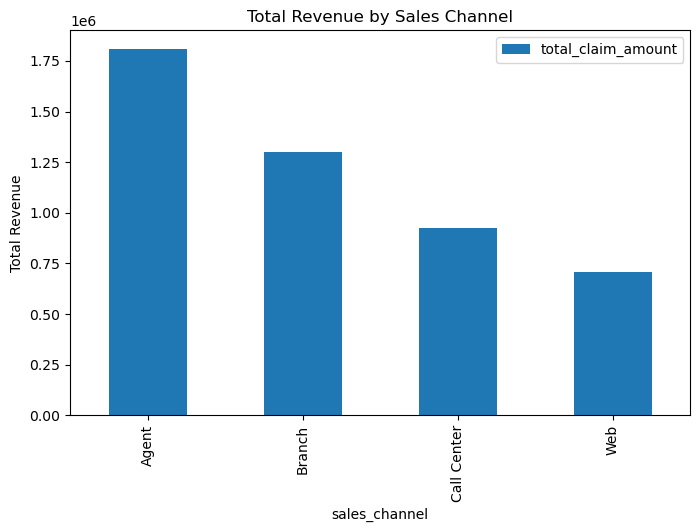

In [17]:
sales_channel_revenue.plot(
    kind="bar",
    figsize=(8,5),
    title="Total Revenue by Sales Channel",
    ylabel="Total Revenue"
)

In [18]:
values="total_claim_amount"

In [20]:
values="customer_lifetime_value"

In [21]:
# Create pivot table: Average Customer Lifetime Value by Gender and Education

clv_gender_education = pd.pivot_table(
    df,
    values="customer_lifetime_value",
    index="gender",
    columns="education",
    aggfunc="mean"
)

# Round values to 2 decimal places
clv_gender_education = clv_gender_education.round(2)

clv_gender_education

education,Bachelor,College,Doctor,High School or Below,Master
gender,,,,,
F,7874.27,7748.82,7328.51,8675.22,8157.05
M,7703.60,8052.46,7415.33,8149.69,8168.83


In [22]:
clv_gender_education.stack().sort_values(ascending=False)

gender  education           
F       High School or Below    8675.22
M       Master                  8168.83
F       Master                  8157.05
M       High School or Below    8149.69
        College                 8052.46
F       Bachelor                7874.27
        College                 7748.82
M       Bachelor                7703.60
        Doctor                  7415.33
F       Doctor                  7328.51
dtype: float64

<Axes: title={'center': 'Average Customer Lifetime Value by Gender and Education'}, xlabel='gender', ylabel='Average Customer Lifetime Value'>

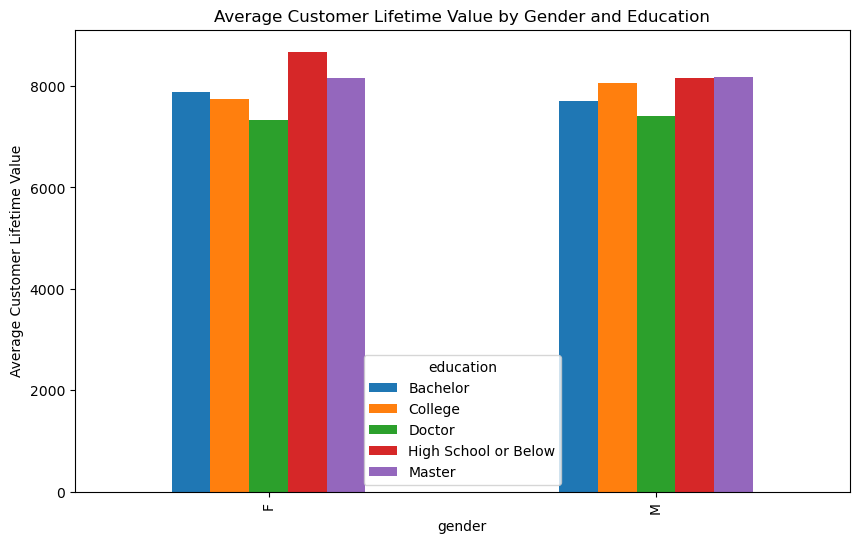

In [23]:
clv_gender_education.plot(
    kind="bar",
    figsize=(10,6),
    title="Average Customer Lifetime Value by Gender and Education",
    ylabel="Average Customer Lifetime Value"
)

2. Create a pivot table that shows the average customer lifetime value per gender and education level. Analyze the resulting table to draw insights.

## Bonus

You work at the customer service department and you want to know which months had the highest number of complaints by policy type category. Create a summary table showing the number of complaints by policy type and month.
Show it in a long format table.

*In data analysis, a long format table is a way of structuring data in which each observation or measurement is stored in a separate row of the table. The key characteristic of a long format table is that each column represents a single variable, and each row represents a single observation of that variable.*

*More information about long and wide format tables here: https://www.statology.org/long-vs-wide-data/*

In [ ]:
# Your code goes here